# Fig. 7 Only — Final ST-HRPNet v1 Variant D

Notebook ringan ini **tidak menjalankan ulang Cell 12B** dan tidak membutuhkan TensorFlow/training.

Notebook hanya membaca hasil eksperimen final yang sudah tersimpan:
- `X_test.npy`
- `y_test.npy`
- `D_MixedPatch50Random50Positive_FPaware_test_prob.npy`
- `D_mixedpatch_final_results.csv`

Kemudian menghasilkan **Fig. 7** dari **Variant D (MixedPatch + FP-aware)** dengan **validation-selected threshold** yang dibaca dari tabel hasil eksperimen final.

> Jalankan **Run All**. Jika folder proyek berbeda, ubah hanya `BASE_DIR`.


In [1]:
# ============================================================
# FIG. 7 QUICK LOAD — FINAL VARIANT D ONLY
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. PROJECT PATH
# ------------------------------------------------------------
BASE_DIR = Path(r"D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program")

D_VARIANT_NAME = "D_MixedPatch50Random50Positive_FPaware"

EXPECTED = {
    "X_test": BASE_DIR / "taac_checkpoints_v3" / "X_test.npy",
    "y_test": BASE_DIR / "taac_checkpoints_v3" / "y_test.npy",
    "D_test_prob": (
        BASE_DIR / "outputs" / "TAAC_reexperiment_v3" / "cache"
        / f"{D_VARIANT_NAME}_test_prob.npy"
    ),
    "D_results": (
        BASE_DIR / "outputs" / "TAAC_reexperiment_v3" / "tables"
        / "D_mixedpatch_final_results.csv"
    ),
}

OUTPUT_DIR = BASE_DIR / "outputs" / "TAAC_reexperiment_v3" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. ROBUST FILE LOCATOR
# ------------------------------------------------------------
def locate_file(label, expected_path, exact_name):
    if expected_path.exists():
        return expected_path

    print(f"[INFO] Expected {label} not found at:")
    print("      ", expected_path)
    print(f"[INFO] Searching recursively for {exact_name} ...")

    hits = list(BASE_DIR.rglob(exact_name))
    if not hits:
        raise FileNotFoundError(
            f"\n{label} tidak ditemukan.\n"
            f"File yang dibutuhkan: {exact_name}\n"
            f"Expected path: {expected_path}\n\n"
            "Artinya hasil/checkpoint eksperimen final belum tersimpan pada BASE_DIR ini. "
            "Jangan retrain dulu; cek apakah BASE_DIR mengarah ke folder proyek yang benar."
        )

    # Prefer TAAC_reexperiment_v3 when multiple copies exist.
    preferred = [p for p in hits if "TAAC_reexperiment_v3" in str(p)]
    chosen = preferred[0] if preferred else hits[0]

    print(f"[FOUND] {label}: {chosen}")
    return chosen


x_path = locate_file("X_test", EXPECTED["X_test"], "X_test.npy")
y_path = locate_file("y_test", EXPECTED["y_test"], "y_test.npy")
prob_path = locate_file(
    "D_test_prob",
    EXPECTED["D_test_prob"],
    f"{D_VARIANT_NAME}_test_prob.npy"
)
results_path = locate_file(
    "D_results",
    EXPECTED["D_results"],
    "D_mixedpatch_final_results.csv"
)


# ------------------------------------------------------------
# 3. LOAD FINAL EXPERIMENT OUTPUT
# ------------------------------------------------------------
X_test = np.load(x_path)
y_test = np.load(y_path)
D_test_prob = np.load(prob_path)
D_results = pd.read_csv(results_path)

print("\nShapes")
print("X_test      :", X_test.shape)
print("y_test      :", y_test.shape)
print("D_test_prob :", D_test_prob.shape)

# Basic compatibility checks
if len(X_test) != len(y_test) or len(y_test) != len(D_test_prob):
    raise ValueError(
        "Jumlah test samples tidak sama: "
        f"X_test={len(X_test)}, y_test={len(y_test)}, D_test_prob={len(D_test_prob)}"
    )

if D_test_prob.shape[:3] != y_test.shape[:3]:
    raise ValueError(
        f"Spatial shape mismatch: y_test={y_test.shape}, D_test_prob={D_test_prob.shape}"
    )


# ------------------------------------------------------------
# 4. READ FINAL VALIDATION-SELECTED THRESHOLD
# ------------------------------------------------------------
# Prefer exact final Variant D row (not fixed-threshold row).
model_col = "model" if "model" in D_results.columns else None

if model_col:
    rows = D_results[
        D_results[model_col].astype(str).eq(D_VARIANT_NAME)
    ].copy()
else:
    rows = D_results.copy()

if "selected_threshold_from_validation" not in D_results.columns:
    raise KeyError(
        "Kolom 'selected_threshold_from_validation' tidak ada pada D_mixedpatch_final_results.csv."
    )

if rows.empty:
    # fallback: choose row not marked FixedThreshold and closest to manuscript-final metrics
    rows = D_results[
        ~D_results.get("model", pd.Series([""] * len(D_results)))
        .astype(str).str.contains("FixedThreshold", case=False, na=False)
    ].copy()

if rows.empty:
    raise RuntimeError("Baris hasil final Variant D tidak ditemukan pada CSV.")

FINAL_THRESHOLD = float(rows.iloc[-1]["selected_threshold_from_validation"])

print("\nFinal Variant D verification")
print("Model     :", D_VARIANT_NAME)
print("Threshold :", FINAL_THRESHOLD)

# This manuscript uses the final validation-selected threshold 0.05.
if not np.isclose(FINAL_THRESHOLD, 0.05, atol=1e-8):
    raise RuntimeError(
        f"STOP: threshold pada hasil final adalah {FINAL_THRESHOLD:.4f}, bukan 0.05. "
        "Jangan membuat Fig. 7 sampai file hasil eksperimen yang benar digunakan."
    )

# Optional metric verification when columns exist
for col in ["iou", "dice_f1", "recall", "specificity", "mcc", "pr_auc",
            "actual_positive_ratio", "predicted_positive_ratio"]:
    if col in rows.columns:
        print(f"{col:26s}: {float(rows.iloc[-1][col]):.6f}")

print("\n[OK] Final Variant D data loaded. Lanjut ke cell Fig. 7.")


Shapes
X_test      : (21, 4, 256, 256, 4)
y_test      : (21, 256, 256, 1)
D_test_prob : (21, 256, 256, 1)

Final Variant D verification
Model     : D_MixedPatch50Random50Positive_FPaware
Threshold : 0.05
iou                       : 0.442038
dice_f1                   : 0.613074
recall                    : 0.659636
specificity               : 0.997888
mcc                       : 0.612839
pr_auc                    : 0.556532
actual_positive_ratio     : 0.004272
predicted_positive_ratio  : 0.004921

[OK] Final Variant D data loaded. Lanjut ke cell Fig. 7.


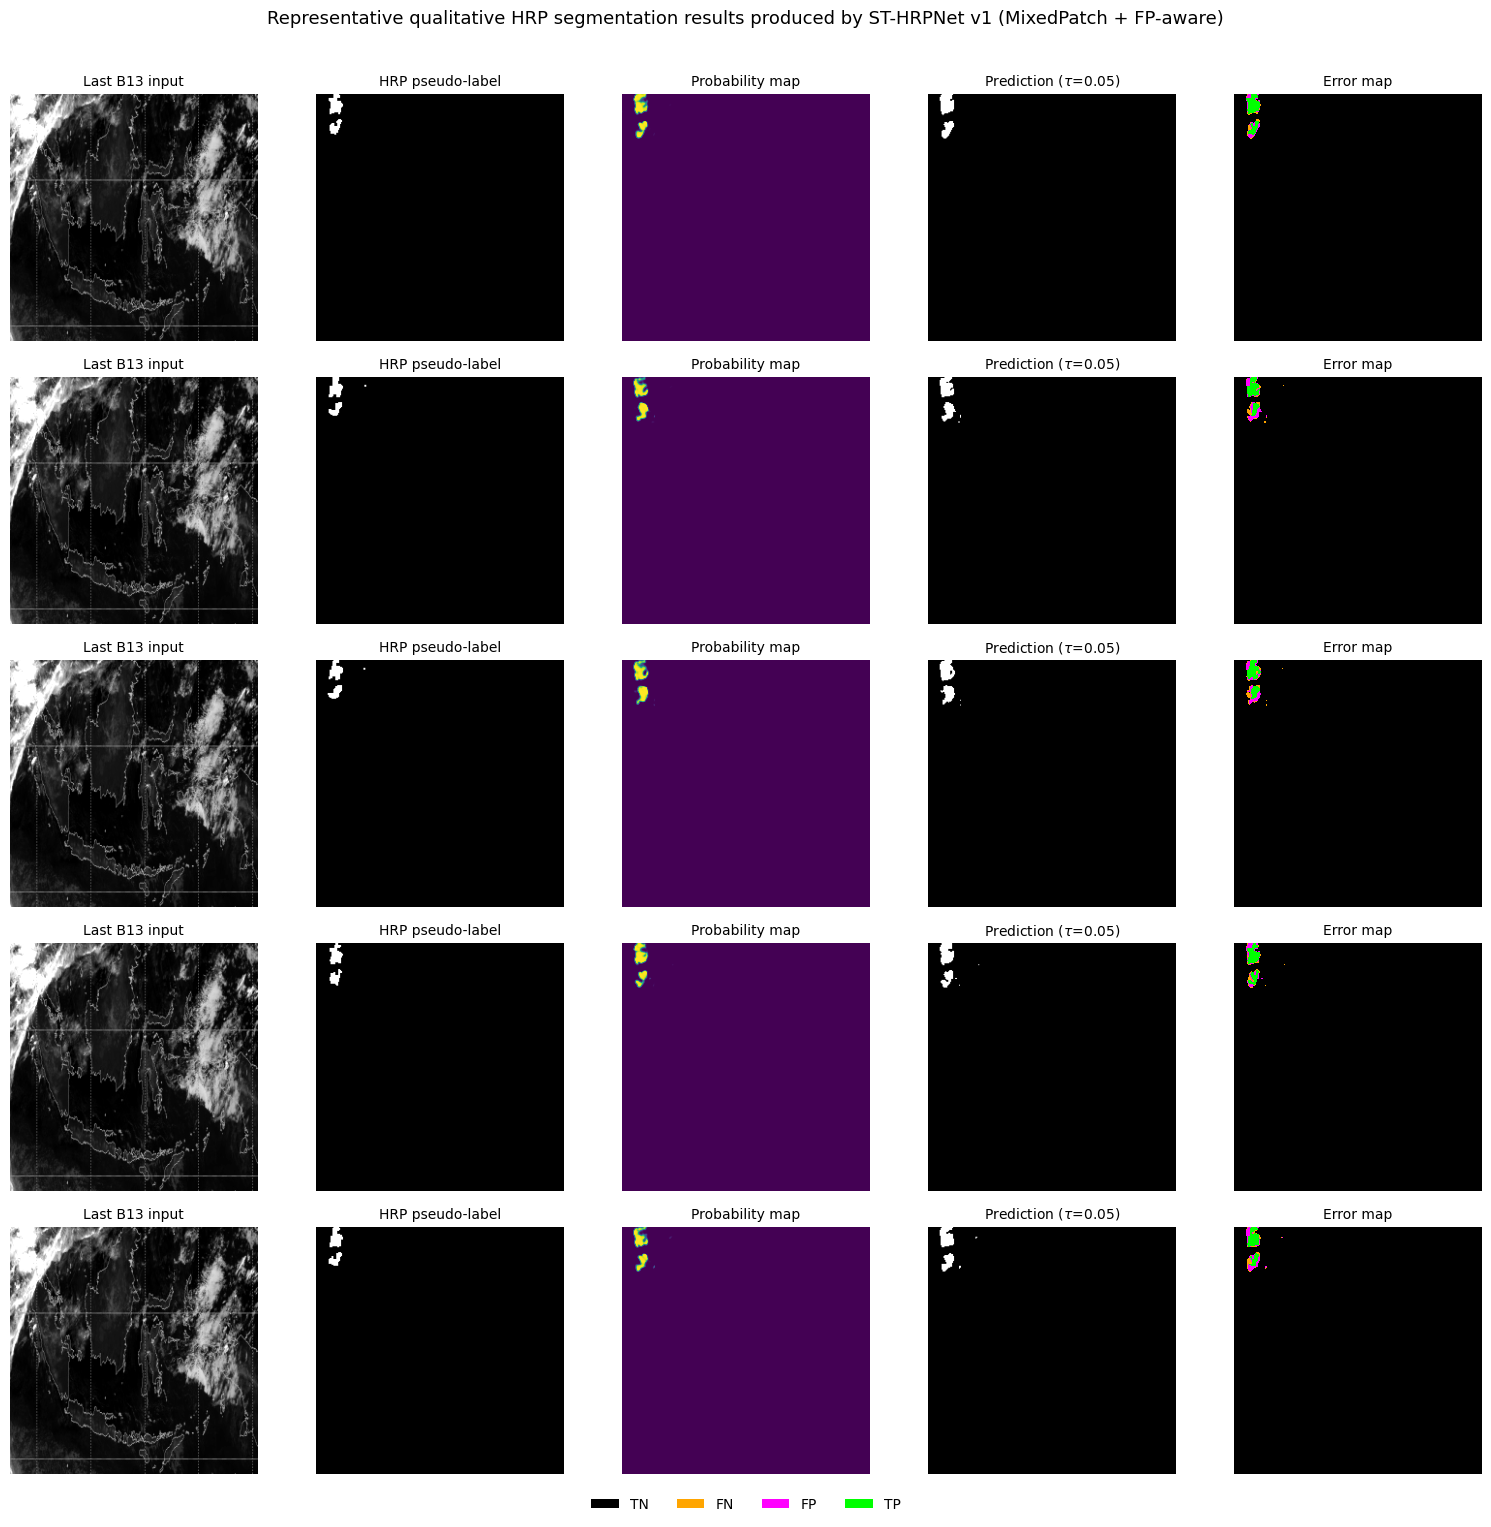


FINAL FIG. 7 SAVED
PNG: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\Fig7_FINAL_STHRPNet_VariantD_tau0p05.png
PDF: D:\RISETKOLABORASI\Artikel Siap Kirim\QUANTUM\Program\outputs\TAAC_reexperiment_v3\figures\Fig7_FINAL_STHRPNet_VariantD_tau0p05.pdf
Threshold used: 0.05
Selected test indices: [9, 11, 12, 8, 10]


In [2]:
# ============================================================
# GENERATE FINAL FIG. 7 — VARIANT D, tau = 0.05
# ============================================================

# Select the five most HRP-positive full-image test cases
ratios = np.asarray([float(np.mean(y_test[i])) for i in range(len(y_test))])
selected_indices = np.argsort(-ratios)[:min(5, len(ratios))]

nrows = len(selected_indices)
fig, axes = plt.subplots(nrows, 5, figsize=(15.5, 3.05 * nrows))

if nrows == 1:
    axes = np.expand_dims(axes, axis=0)

# Discrete error map:
# 0 = TN, 1 = FN, 2 = FP, 3 = TP
error_cmap = ListedColormap(["black", "orange", "magenta", "lime"])

for r, idx in enumerate(selected_indices):
    idx = int(idx)

    # Final timestamp / B13
    x_last = X_test[idx, -1]
    b13 = x_last[..., 0]

    # Ground truth
    if y_test.ndim == 4:
        y_true = y_test[idx, ..., 0]
    else:
        y_true = y_test[idx]

    # FINAL D probability
    if D_test_prob.ndim == 4:
        prob = D_test_prob[idx, ..., 0]
    else:
        prob = D_test_prob[idx]

    prob = np.nan_to_num(prob.astype(np.float32), nan=0.0, posinf=1.0, neginf=0.0)
    prob = np.clip(prob, 0.0, 1.0)

    # IMPORTANT: real thresholding from final D probability
    pred = (prob >= FINAL_THRESHOLD).astype(np.uint8)
    gt = (y_true >= 0.5).astype(np.uint8)

    # Categorical error map
    error = np.zeros_like(gt, dtype=np.uint8)  # TN
    error[(gt == 1) & (pred == 0)] = 1         # FN
    error[(gt == 0) & (pred == 1)] = 2         # FP
    error[(gt == 1) & (pred == 1)] = 3         # TP

    panels = [
        (b13, "gray", "Last B13 input"),
        (gt, "gray", "HRP pseudo-label"),
        (prob, "viridis", "Probability map"),
        (pred, "gray", rf"Prediction ($\tau$={FINAL_THRESHOLD:.2f})"),
        (error, error_cmap, "Error map"),
    ]

    for c, (arr, cmap, title) in enumerate(panels):
        axes[r, c].imshow(arr, cmap=cmap, vmin=0, vmax=(3 if c == 4 else None))
        axes[r, c].set_title(title, fontsize=10)
        axes[r, c].axis("off")

    axes[r, 0].set_ylabel(
        f"Case {r+1}\nindex={idx}\nHRP={float(gt.mean()):.4f}",
        fontsize=9
    )

fig.suptitle(
    "Representative qualitative HRP segmentation results produced by "
    "ST-HRPNet v1 (MixedPatch + FP-aware)",
    fontsize=13,
    y=0.995
)

legend_handles = [
    Patch(facecolor="black", label="TN"),
    Patch(facecolor="orange", label="FN"),
    Patch(facecolor="magenta", label="FP"),
    Patch(facecolor="lime", label="TP"),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.002)
)

plt.tight_layout(rect=[0, 0.025, 1, 0.985])

png_path = OUTPUT_DIR / "Fig7_FINAL_STHRPNet_VariantD_tau0p05.png"
pdf_path = OUTPUT_DIR / "Fig7_FINAL_STHRPNet_VariantD_tau0p05.pdf"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("\nFINAL FIG. 7 SAVED")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Threshold used:", FINAL_THRESHOLD)
print("Selected test indices:", selected_indices.tolist())